### Importing libraries + csvs + preliminary data quality checks

In [1]:
#Libraries import
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

In [2]:
#Load data files

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
    
raw_data_dir = project_root / "data" / "raw"

universe = pd.read_csv(raw_data_dir / "universe_50.csv", parse_dates=["Date"])
amzn = pd.read_csv(raw_data_dir / "amzn.csv", parse_dates=["Date"])

print("50-company dataset:", universe.shape)
print("Companies:", universe["Ticker"].nunique())
display(universe.head())

print("Amazon dataset:", amzn.shape)
display(amzn.head())

50-company dataset: (125650, 8)
Companies: 50


,Date,Open,High,Low,Close,Adj Close,Volume,Ticker
0,2016-09-01,26.535000,26.700001,26.405001,26.682501,24.407614,106806000,AAPL
1,2016-09-02,26.924999,27.000000,26.705000,26.932501,24.636307,107210000,AAPL
2,2016-09-06,26.975000,27.075001,26.877501,26.924999,24.629438,107521600,AAPL
3,2016-09-07,26.957500,27.190001,26.767500,27.090000,24.780375,169457200,AAPL
4,2016-09-08,26.812500,26.817499,26.309999,26.379999,24.130911,212008000,AAPL


Amazon dataset: (2513, 6)


,Date,Open,High,Low,Adj_Close,Volume
0,2016-09-01,38.544998,38.602001,38.337502,38.530998,35846000
1,2016-09-02,38.705502,38.799999,38.584999,38.622002,43636000
2,2016-09-06,38.702000,39.473999,38.511002,39.443501,74396000
3,2016-09-07,39.476501,39.539501,39.216499,39.223999,48492000
4,2016-09-08,39.194500,39.325001,39.071999,39.202999,40610000


In [3]:
#Check date range
print("50 company date range:")
print(universe["Date"].min(), "to", universe["Date"].max())

print("\nAmazon date range:")
print(amzn["Date"].min(), "to", amzn["Date"].max())

#check ordering of dates - ensure rows aren't shuffled
print("\nChronological ordering:")
print("50-company sorted within each ticker:", universe.groupby("Ticker")["Date"].apply
     ( lambda dates: dates.is_monotonic_increasing).all() )
print("Amazon sorted by date:", amzn["Date"].is_monotonic_increasing)

#Check for duplicates 
print("\nDuplicate stock-date records:")
print(universe.duplicated(["Ticker", "Date"]).sum())

print("\nDuplicate Amazon date records:")
print(amzn["Date"].duplicated().sum())

#Check for missing values
print("\nMissing values in 50-company data:")
display(universe.isna().sum().to_frame("Missing_Count"))

print("\nMissing values - Amazon data:")
display(amzn.isna().sum().to_frame("Missing_Count"))

50 company date range:
2016-09-01 00:00:00 to 2026-09-01 00:00:00

Amazon date range:
2016-09-01 00:00:00 to 2026-09-01 00:00:00

Chronological ordering:
50-company sorted within each ticker: True
Amazon sorted by date: True

Duplicate stock-date records:
0

Duplicate Amazon date records:
0

Missing values in 50-company data:


,Missing_Count
Date,0
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Ticker,0



Missing values - Amazon data:


,Missing_Count
Date,0
Open,0
High,0
Low,0
Adj_Close,0
Volume,0


### Preliminary Stock Universe Statistics

In [7]:
# Check for structural anomalies
raw_cols = ["Open", "Low", "High", "Close", "Volume"]

#there should be no days where high price is lower than low price
univ_inconsistent_prices = universe[universe['High'] < universe['Low']] 
#no days where low is lower than opening, pr high or lower than opening 
inconsistent_ohl = universe[ (universe["High"] < universe["Open"]) |
    (universe["Low"] > universe["Open"])]
#no days where negative prices are recorded
univ_negative_prices = universe[ (universe[raw_cols]<= 0).any(axis=1) ] 

print(f"Number of days where High < Low: {len(univ_inconsistent_prices)}")
print(f"Rows with inconsistent Open/High/Low: {len(inconsistent_ohl)}")
print(f"Number of days with negative/zero prices: {len(univ_negative_prices)}")

Number of days where High < Low: 0
Rows with inconsistent Open/High/Low: 0
Number of days with negative/zero prices: 0


In [9]:
#Creating return and log return columns for stock companies 
universe['Daily_Return'] =( universe.groupby("Ticker")["Adj Close"].pct_change() )

universe["Log_Return"] = ( 
    universe.groupby("Ticker")["Adj Close"].transform(lambda s: np.log(s /s.shift(1))) )

In [11]:
#Creating summary statsitics table for overview of return behavior acrosss companies
return_summary = universe.groupby("Ticker")["Daily_Return"].agg(
    ["mean", "median", "std", "min", "max"]
)
print("Distributionn of company-level daily retun statistics:")
display(return_summary.describe())

Distributionn of company-level daily retun statistics:


,mean,median,std,min,max
count,50.000000,50.000000,50.000000,50.000000,50.000000
mean,0.000808,0.000815,0.019043,-0.161719,0.163556
std,0.000475,0.000428,0.005582,0.053585,0.056705
min,0.000098,-0.000066,0.011629,-0.351166,0.064796
25%,0.000512,0.000598,0.015882,-0.194918,0.127148
50%,0.000705,0.000825,0.017600,-0.146078,0.148991
75%,0.000918,0.001022,0.020776,-0.127451,0.180972
max,0.002463,0.002633,0.037498,-0.077346,0.359488


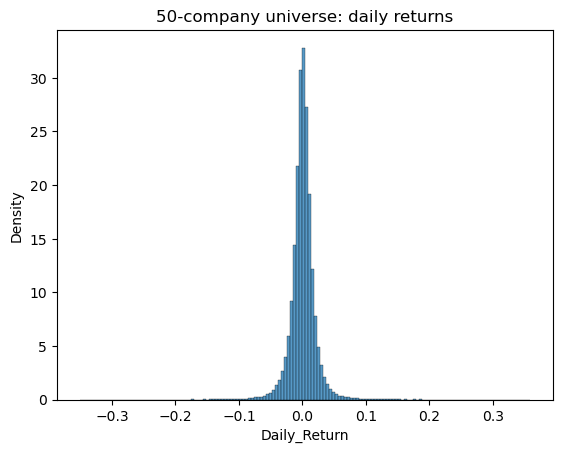

In [13]:
#Return distribution plot for daily returns
sns.histplot( universe["Daily_Return"].dropna(), bins=150, stat='density')
plt.title("50-company universe: daily returns")
plt.show()

In [15]:
#Looking at outliers in our 50-company universe
universe = universe.sort_values(["Ticker", "Date"]).copy()

universe["Pct_Change_1d"] = (universe.groupby("Ticker")["Adj Close"].pct_change())
universe["Pct_Change_2d"] = (universe.groupby("Ticker")["Adj Close"].pct_change(periods=2))

#Flag unusually large movements 
extreme_moves_1d = universe[universe["Pct_Change_1d"].abs() > 0.15]
extreme_moves_2d = universe[universe["Pct_Change_2d"].abs() > 0.15]

print("Extreme 1-day moves:", len(extreme_moves_1d))
print("Extreme 2-day moves:", len(extreme_moves_2d))

Extreme 1-day moves: 110
Extreme 2-day moves: 283


In [17]:
extreme_moves_1d[
    ["Date", "Ticker", "Adj Close", "Pct_Change_1d"]
].sort_values("Pct_Change_1d")

,Date,Ticker,Adj Close,Pct_Change_1d
84346,2022-04-20,NFLX,22.618999,-0.351166
76755,2022-02-03,META,235.504425,-0.263901
59790,2024-08-02,INTC,21.344599,-0.260585
91356,2020-03-16,O,37.560112,-0.249304
28526,2020-03-09,COP,26.957304,-0.248401
...,...,...,...,...
19675,2024-12-13,AVGO,220.973633,0.244326
28537,2020-03-24,COP,24.322498,0.252139
33671,2020-08-26,CRM,267.218750,0.260449
88005,2016-11-11,NVDA,2.158154,0.298067


### Preliminary Amazon Statistics Check + EDA

In [20]:
#Checking structural anomalies
a_raw_cols = ["Open", "Low", "High", "Adj_Close", "Volume"]

#there should be no days where high price is lower than low price
a_inconsistent_prices = amzn[amzn['High'] < amzn['Low']] 
#no days where low is lower than opening, pr high or lower than opening 
a_ohl = amzn[ (amzn["High"] < amzn["Open"]) |
    (amzn["Low"] > amzn["Open"])]
#no days where negative prices are recorded
a_negative_prices = amzn[ (amzn[a_raw_cols]<= 0).any(axis=1) ] 

print(f"Number of days where High < Low: {len(a_inconsistent_prices)}")
print(f"Rows with inconsistent Open/High/Low: {len(a_ohl)}")
print(f"Number of days with negative/zero prices: {len(a_negative_prices)}")

Number of days where High < Low: 0
Rows with inconsistent Open/High/Low: 0
Number of days with negative/zero prices: 0


In [22]:
#Creating return columns 

amzn["Daily_Return"] = amzn["Adj_Close"].pct_change()

amzn["Log_Return"] = np.log( amzn["Adj_Close"]/amzn["Adj_Close"].shift(1))

In [24]:
#A look at Amazon's daily return statistics
print("\nAmazon daily return statistics:")
display(amzn["Daily_Return"].describe())


Amazon daily return statistics:


count    2512.000000
mean        0.000969
std         0.020868
min        -0.140494
25%        -0.009208
50%         0.001008
75%         0.011711
max         0.153206
Name: Daily_Return, dtype: float64

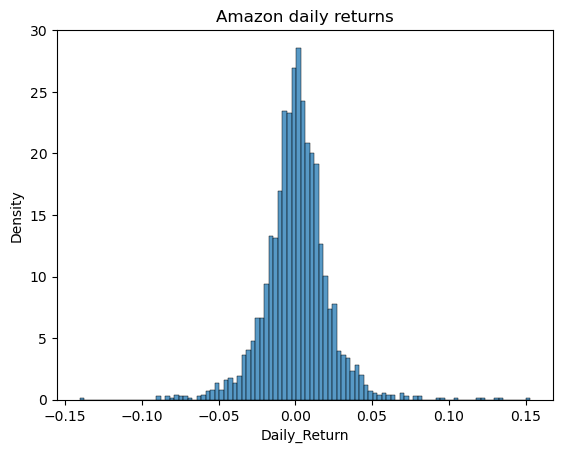

In [26]:
#Visualize return distribution
sns.histplot( amzn["Daily_Return"].dropna(), bins=100, stat='density')
plt.title("Amazon daily returns")
plt.show()

In [28]:
#Outlier Check

amzn = amzn.sort_values("Date").copy()

amzn["Pct_Change_1d"] = amzn["Adj_Close"].pct_change()
amzn["Pct_Change_2d"] = amzn["Adj_Close"].pct_change(periods=2)

a_extreme_moves_1d = amzn[amzn["Pct_Change_1d"].abs() > 0.15]

a_extreme_moves_2d = amzn[amzn["Pct_Change_2d"].abs() > 0.15]

print("Extreme 1-day moves:", len(a_extreme_moves_1d))
print("Extreme 2-observation moves:", len(a_extreme_moves_2d))

Extreme 1-day moves: 1
Extreme 2-observation moves: 3


In [30]:
#Inspect flagged outliers
a_extreme_moves_1d[ ["Date", "Adj_Close", "Pct_Change_1d"]].sort_values("Pct_Change_1d")

,Date,Adj_Close,Pct_Change_1d
2490,2026-07-31,271.579987,0.153206


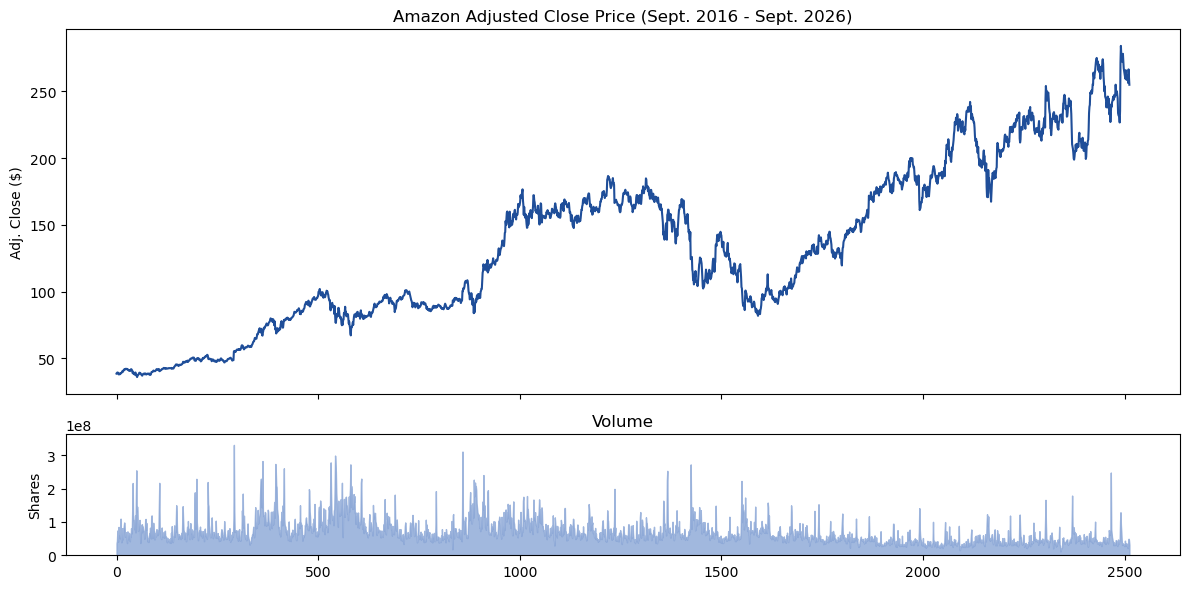

In [32]:
#A look at amazon's close price over time
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot(amzn.index, amzn["Adj_Close"], color="#1f4e99", linewidth=1.5)
axes[0].set_title("Amazon Adjusted Close Price (Sept. 2016 - Sept. 2026)")
axes[0].set_ylabel("Adj. Close ($)")

# Using fill_between to ensure the volume bars scale beautifully and remain perfectly visible
axes[1].fill_between(amzn.index, amzn["Volume"], color="#8aa6d6", alpha=0.8)
axes[1].set_title("Volume")
axes[1].set_ylabel("Shares")
axes[1].set_ylim(0, amzn["Volume"].max() * 1.1)  # Give some headroom

plt.tight_layout()
plt.show()

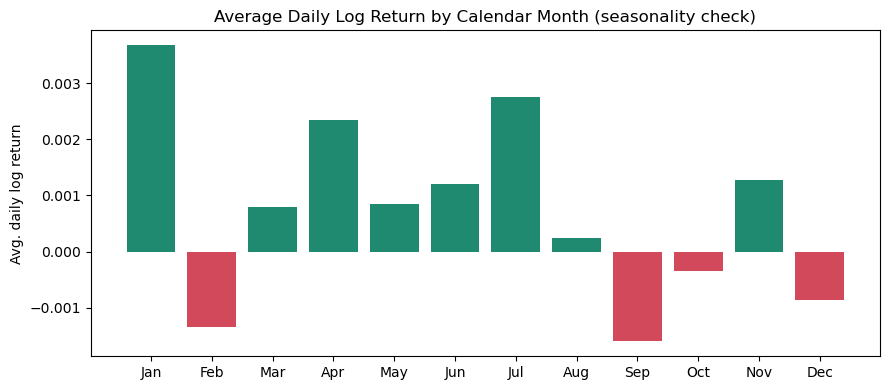

In [34]:
#Amazon seasonality check 
amzn['Date'] = pd.to_datetime(amzn['Date'])
amzn.set_index('Date', inplace=True)

monthly = amzn["Log_Return"].groupby(amzn.index.month).mean()
plt.figure(figsize=(9, 4))
plt.bar(monthly.index, monthly.values, color=["#1f8a70" if v > 0 else "#d1495b" for v in monthly.values])
plt.xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
plt.title("Average Daily Log Return by Calendar Month (seasonality check)")
plt.ylabel("Avg. daily log return")
plt.tight_layout()
plt.show()

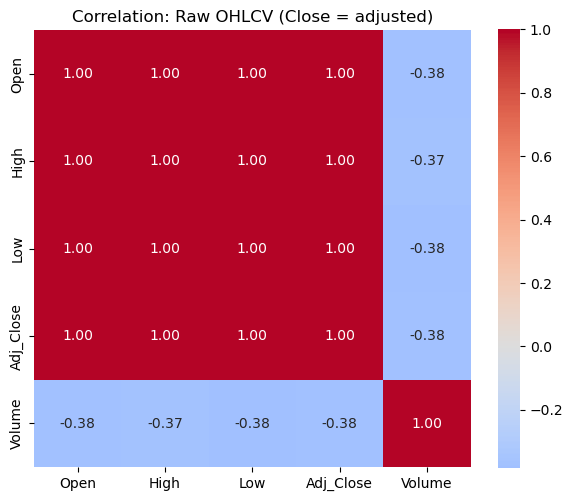

In [39]:
#A look at correlation between variables
ohlcv_cols = ["Open", "High", "Low", "Adj_Close", "Volume"]
corr_ohlcv = amzn[ohlcv_cols].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_ohlcv, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Correlation: Raw OHLCV (Close = adjusted)")
plt.tight_layout()
plt.show()

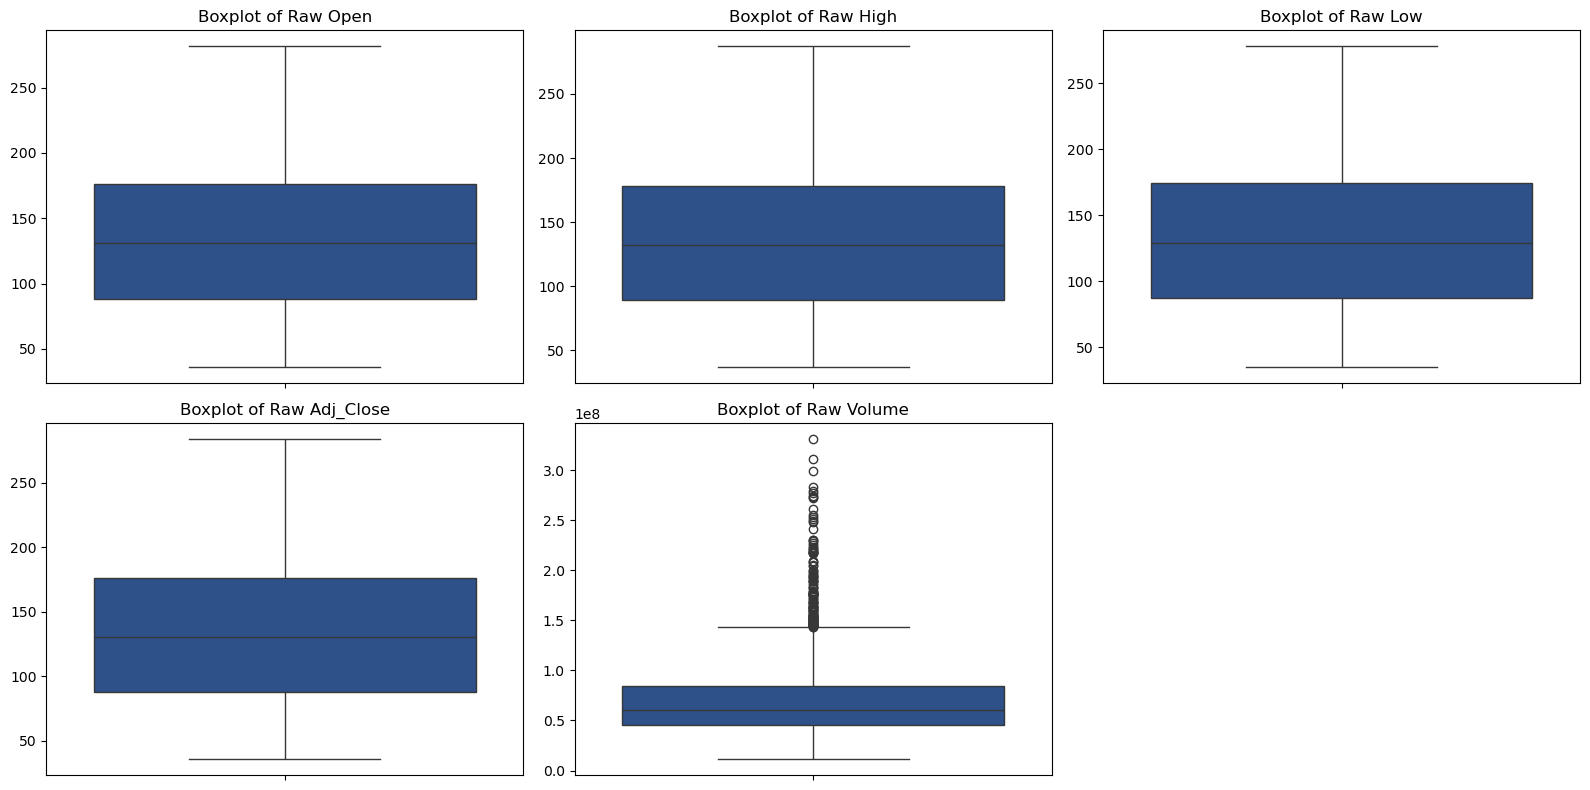

In [41]:
#A look at raw columns' distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.ravel()

for i, col in enumerate(ohlcv_cols):
    sns.boxplot(data=amzn[ohlcv_cols], y=col, ax=axes[i], color='#1f4e99')
    axes[i].set_title(f'Boxplot of Raw {col}')
    axes[i].set_ylabel('')

# Turn off the last unused subplot
axes[-1].axis('off')
plt.tight_layout()
plt.show()

### Target Distribution

In [131]:
#Establish consistent targets and training period (2016 - 2024)
rannum = 42
horizon = [1, 5, 21, 63]
train_end = pd.Timestamp("2024-09-01")
step_size = 63

In [107]:
#Function to create target up/down columns
def make_target_labels(close, horizon):
    labels = pd.DataFrame(index=close.index)

    for h in horizon:
        future_close = close.shift(-h)
        fwd = np.log(future_close / close)

        labels[f"fwd_ret_{h}d"] = fwd
        
        #keep unknown future directions as mssing
        direction = pd.Series(np.nan, index=close.index)
        valid = fwd.notna()
        direction.loc[valid] = (fwd.loc[valid] > 0).astype(int)
        labels[f"direction_{h}d"] = direction
        
        #date when forward return's endpoint occurs 
        labels[f"label_end_{h}d"] = pd.Series( close.index, index=close.index).shift(-h)

    return labels 

#make labels
label_df = make_target_labels(amzn["Adj_Close"], horizon)

# Remove any old target columns before joining, so rerunning is safe
target_cols = [
    col for col in label_df.columns
    if col in amzn.columns
]
amzn = amzn.drop(columns=target_cols)

#put target labels into amazon dataset
amzn = amzn.join(label_df)

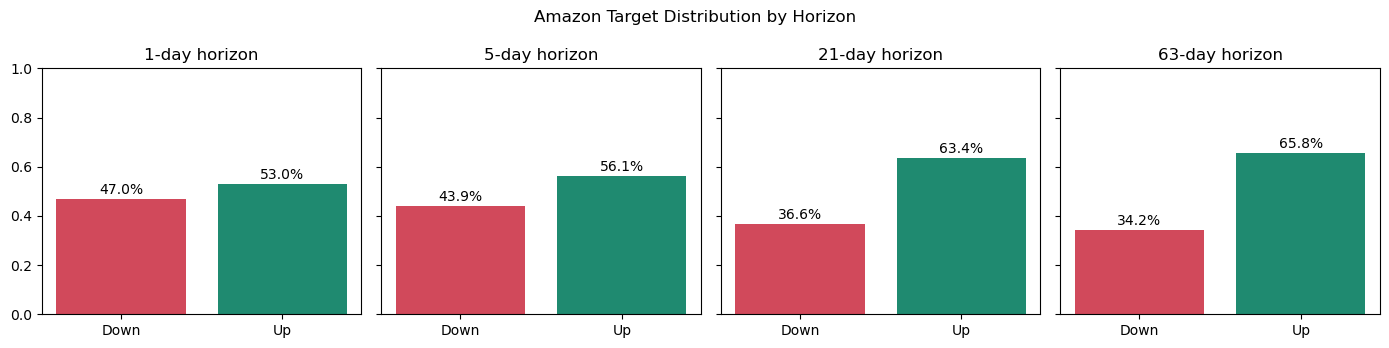

In [109]:
#Plot target distribution
fig, axes = plt.subplots(1, 4, figsize=(14, 3.5), sharey=True)

for ax, h in zip(axes, horizon):
    counts= amzn[f"direction_{h}d"].value_counts(normalize=True).sort_index()
    ax.bar(["Down", "Up"], counts.values, color=["#d1495b", "#1f8a70"])
    ax.set_title(f"{h}-day horizon")
    ax.set_ylim(0, 1)
    
    for i, v in enumerate(counts.values):
        ax.text(i, v + 0.02, f"{v:.1%}", ha="center")
        
fig.suptitle("Amazon Target Distribution by Horizon")
plt.tight_layout()
plt.show()


### Amazon Baseline with walk-forward validation

In [159]:
#Importing models and metrics
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)

In [117]:
#Install XGBoost 
!pip install xgboost
from xgboost import XGBClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 19.6 MB/s eta 0:00:00m eta 0:00:010:01


In [141]:
#Function that use label-end dates to purge data - prevents leakage for validation folds
def make_folds(index, train_end, horizon, step_size=63, embargo_size=None):
    embargo_size = horizon if embargo_size is None else embargo_size
    dates= pd.DatetimeIndex(index)

    if not dates.is_monotonic_increasing:
        raise ValueError("Data has not been sorted chronologically.")
    #First test observation on or after the cutoff
    pos = dates.searchsorted(pd.Timestamp(train_end))
    folds = []
    
    while pos < len(dates): 
        test_end = min(pos + step_size, len(dates))
        folds.append((pos, test_end))
        
        #Leave a gap after test fold - prevent leakage
        pos = test_end + embargo_size

    return folds

In [133]:
#Function to set up some models for baseline testing

def make_models():
    return {
        "Majority baseline": None,
        "Logistic Regression": make_pipeline( StandardScaler(), 
                                            LogisticRegression( 
                                                max_iter=2000, random_state=rannum)),
        "Random Forest": RandomForestClassifier( n_estimators=200, min_samples_leaf=5,
                                               random_state=rannum, n_jobs=-1),
        "XGBoost": XGBClassifier( n_estimators=200, max_depth=3, random_state=rannum, 
                                n_jobs=-1, verbosity=0)
    }

Usable obs: 2512
Walk-forward test windows: 8

Majority baseline | 1-day horizon
OOS accuracy: 0.5193
OOS observations: 493
              precision    recall  f1-score   support

        Down       0.00      0.00      0.00       237
          Up       0.52      1.00      0.68       256

    accuracy                           0.52       493
   macro avg       0.26      0.50      0.34       493
weighted avg       0.27      0.52      0.35       493



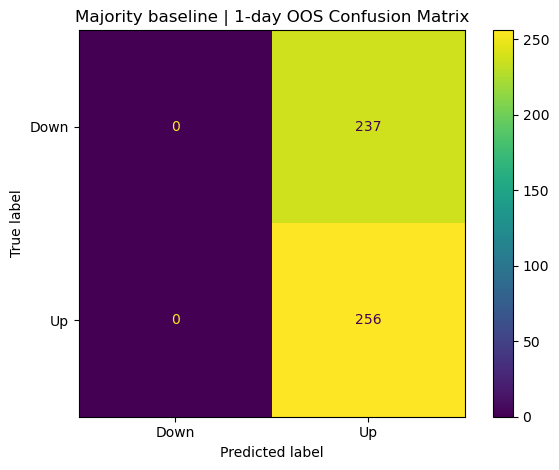


Logistic Regression | 1-day horizon
OOS accuracy: 0.4949
OOS observations: 493
              precision    recall  f1-score   support

        Down       0.49      0.89      0.63       237
          Up       0.56      0.13      0.21       256

    accuracy                           0.49       493
   macro avg       0.52      0.51      0.42       493
weighted avg       0.52      0.49      0.41       493



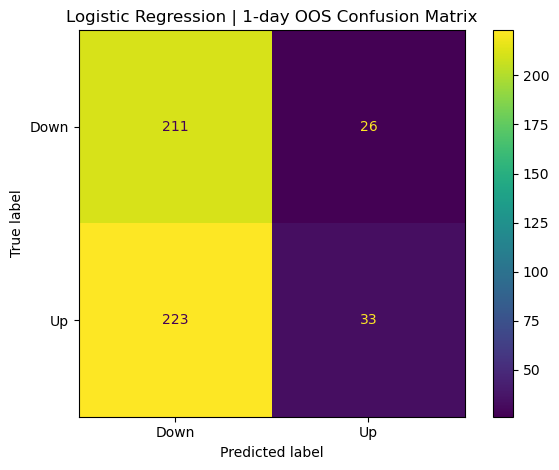


Random Forest | 1-day horizon
OOS accuracy: 0.5213
OOS observations: 493
              precision    recall  f1-score   support

        Down       0.50      0.68      0.58       237
          Up       0.56      0.38      0.45       256

    accuracy                           0.52       493
   macro avg       0.53      0.53      0.51       493
weighted avg       0.53      0.52      0.51       493



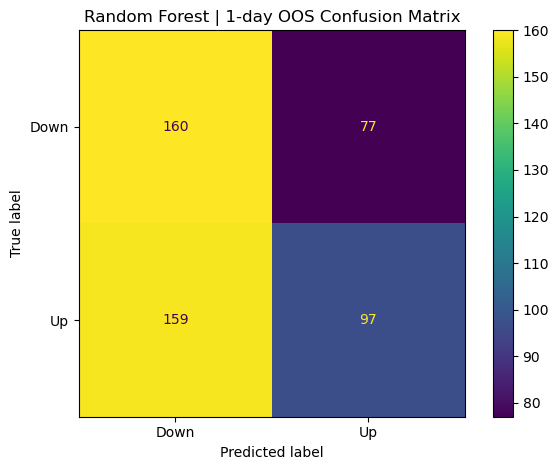


XGBoost | 1-day horizon
OOS accuracy: 0.5051
OOS observations: 493
              precision    recall  f1-score   support

        Down       0.49      0.57      0.52       237
          Up       0.53      0.45      0.49       256

    accuracy                           0.51       493
   macro avg       0.51      0.51      0.50       493
weighted avg       0.51      0.51      0.50       493



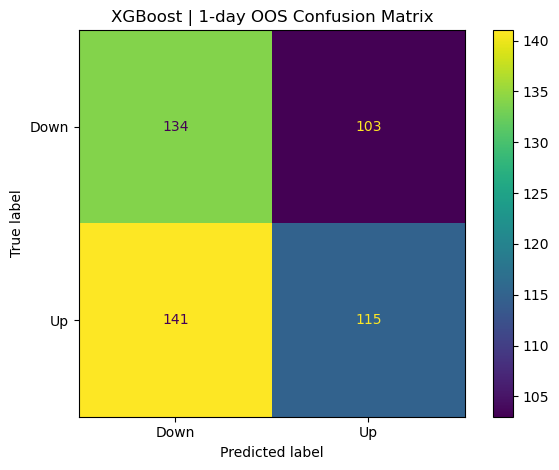

Usable obs: 2508
Walk-forward test windows: 8

Majority baseline | 5-day horizon
OOS accuracy: 0.5315
OOS observations: 461
              precision    recall  f1-score   support

        Down       0.00      0.00      0.00       216
          Up       0.53      1.00      0.69       245

    accuracy                           0.53       461
   macro avg       0.27      0.50      0.35       461
weighted avg       0.28      0.53      0.37       461



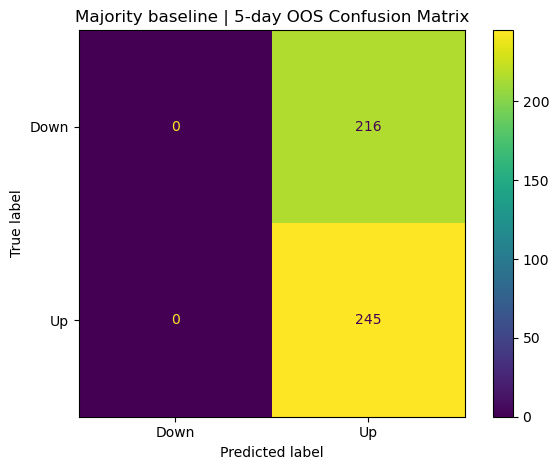


Logistic Regression | 5-day horizon
OOS accuracy: 0.4794
OOS observations: 461
              precision    recall  f1-score   support

        Down       0.47      1.00      0.64       216
          Up       0.86      0.02      0.05       245

    accuracy                           0.48       461
   macro avg       0.67      0.51      0.34       461
weighted avg       0.68      0.48      0.33       461



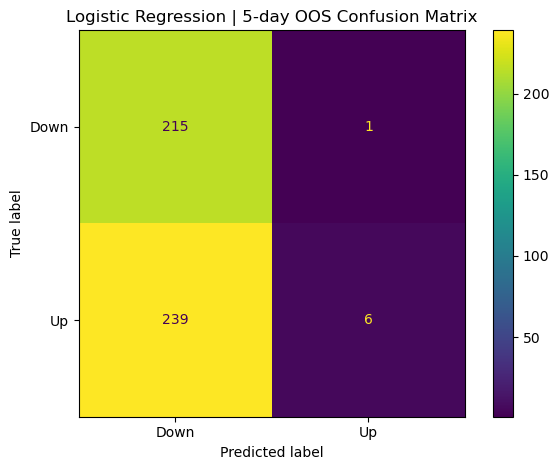


Random Forest | 5-day horizon
OOS accuracy: 0.5445
OOS observations: 461
              precision    recall  f1-score   support

        Down       0.51      0.78      0.62       216
          Up       0.63      0.34      0.44       245

    accuracy                           0.54       461
   macro avg       0.57      0.56      0.53       461
weighted avg       0.58      0.54      0.52       461



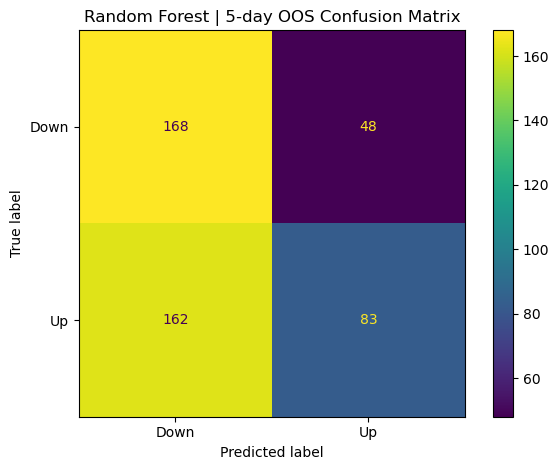


XGBoost | 5-day horizon
OOS accuracy: 0.5033
OOS observations: 461
              precision    recall  f1-score   support

        Down       0.48      0.71      0.57       216
          Up       0.56      0.32      0.41       245

    accuracy                           0.50       461
   macro avg       0.52      0.52      0.49       461
weighted avg       0.52      0.50      0.48       461



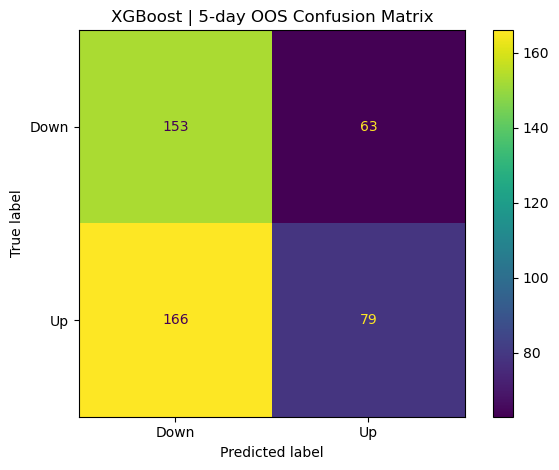

Usable obs: 2492
Walk-forward test windows: 6

Majority baseline | 21-day horizon
OOS accuracy: 0.5787
OOS observations: 375
              precision    recall  f1-score   support

        Down       0.00      0.00      0.00       158
          Up       0.58      1.00      0.73       217

    accuracy                           0.58       375
   macro avg       0.29      0.50      0.37       375
weighted avg       0.33      0.58      0.42       375



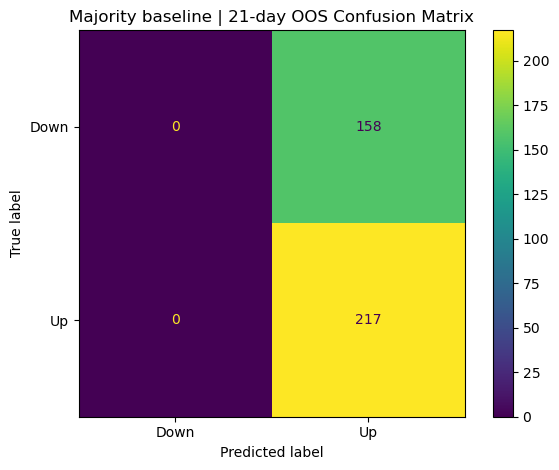


Logistic Regression | 21-day horizon
OOS accuracy: 0.5920
OOS observations: 375
              precision    recall  f1-score   support

        Down       0.51      0.75      0.61       158
          Up       0.73      0.47      0.57       217

    accuracy                           0.59       375
   macro avg       0.62      0.61      0.59       375
weighted avg       0.63      0.59      0.59       375



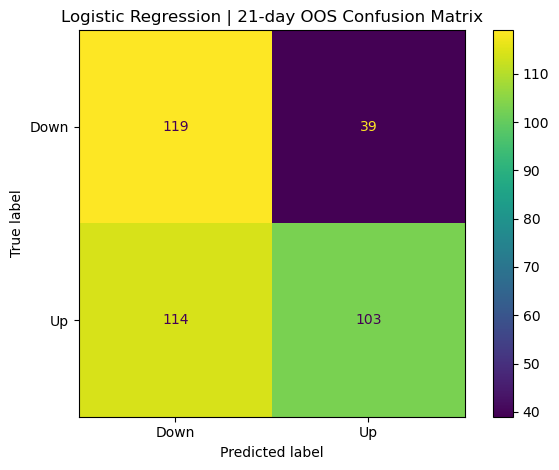


Random Forest | 21-day horizon
OOS accuracy: 0.6187
OOS observations: 375
              precision    recall  f1-score   support

        Down       0.54      0.67      0.60       158
          Up       0.71      0.58      0.64       217

    accuracy                           0.62       375
   macro avg       0.62      0.63      0.62       375
weighted avg       0.64      0.62      0.62       375



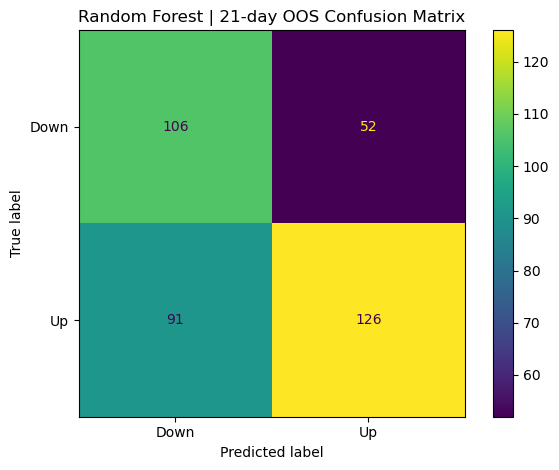


XGBoost | 21-day horizon
OOS accuracy: 0.5920
OOS observations: 375
              precision    recall  f1-score   support

        Down       0.51      0.68      0.58       158
          Up       0.69      0.53      0.60       217

    accuracy                           0.59       375
   macro avg       0.60      0.60      0.59       375
weighted avg       0.62      0.59      0.59       375



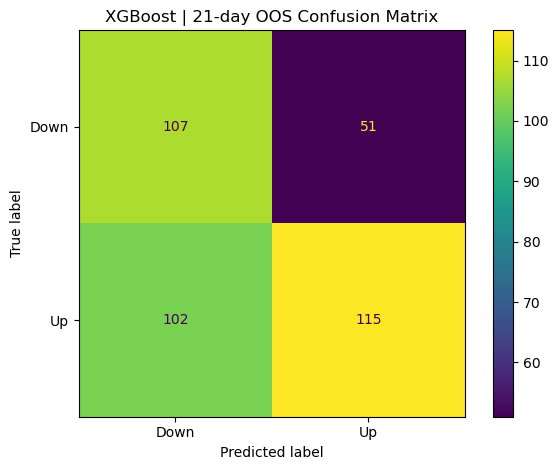

Usable obs: 2450
Walk-forward test windows: 4

Majority baseline | 63-day horizon
OOS accuracy: 0.7590
OOS observations: 249
              precision    recall  f1-score   support

        Down       0.00      0.00      0.00        60
          Up       0.76      1.00      0.86       189

    accuracy                           0.76       249
   macro avg       0.38      0.50      0.43       249
weighted avg       0.58      0.76      0.66       249



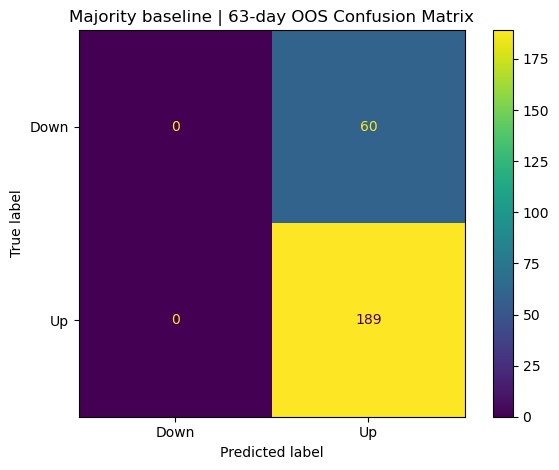


Logistic Regression | 63-day horizon
OOS accuracy: 0.4378
OOS observations: 249
              precision    recall  f1-score   support

        Down       0.30      1.00      0.46        60
          Up       1.00      0.26      0.41       189

    accuracy                           0.44       249
   macro avg       0.65      0.63      0.44       249
weighted avg       0.83      0.44      0.42       249



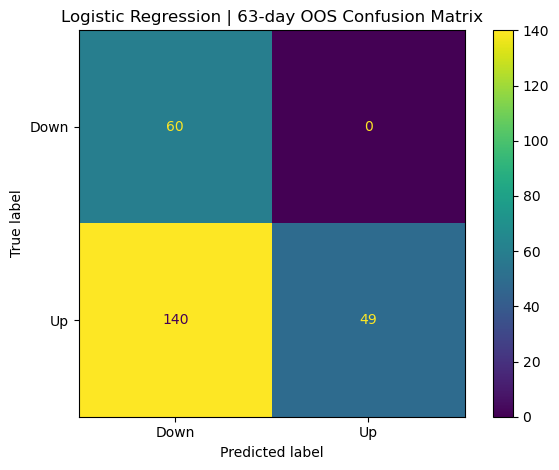


Random Forest | 63-day horizon
OOS accuracy: 0.5382
OOS observations: 249
              precision    recall  f1-score   support

        Down       0.34      1.00      0.51        60
          Up       1.00      0.39      0.56       189

    accuracy                           0.54       249
   macro avg       0.67      0.70      0.54       249
weighted avg       0.84      0.54      0.55       249



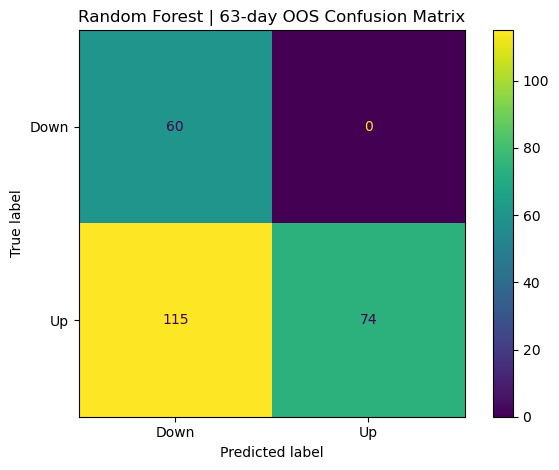


XGBoost | 63-day horizon
OOS accuracy: 0.5622
OOS observations: 249
              precision    recall  f1-score   support

        Down       0.35      0.98      0.52        60
          Up       0.99      0.43      0.60       189

    accuracy                           0.56       249
   macro avg       0.67      0.71      0.56       249
weighted avg       0.83      0.56      0.58       249



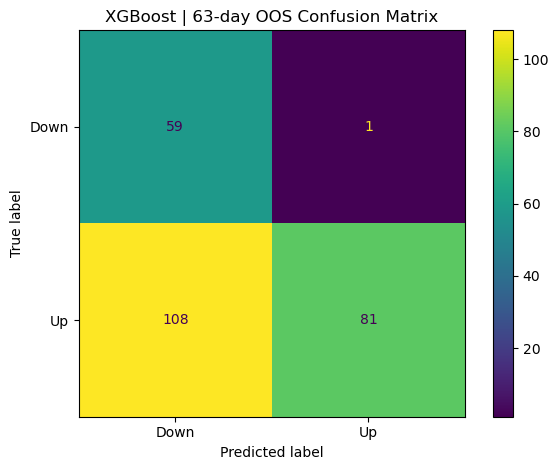


All modeling runs completed.
Total OOS prediction rows: 6312


In [169]:
#define explicit columns for this modeling section
feature_cols = ["Open", "High", "Low", "Adj_Close", "Volume"]
missing_cols = [c for c in feature_cols if c not in amzn.columns]

#store results + reports
all_pred = []
all_reports = []
all_cm = []

#Begin walk-foward expanding modeling session
for h in horizon:
    target_col = f"direction_{h}d"
    label_end_col = f"label_end_{h}d"
    
    #select data portion specific for this horizon examination
    data = amzn[feature_cols].copy()
    data["target"] = amzn[target_col]
    data["label_end"] = pd.to_datetime(amzn[label_end_col])
    
    #make sure columns are all numeric and drop any unusable rows
    data[feature_cols] = data[feature_cols].apply( pd.to_numeric, errors="coerce")
    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna( subset=feature_cols + ["target", "label_end"])

    #separating data portions
    x = data[feature_cols]
    y = data["target"].astype(int)
    label_end = data["label_end"]

    #Make training folds
    folds = make_folds( index=x.index, train_end=train_end, horizon=h, step_size=step_size)
    print("Usable obs:", len(data))
    print("Walk-forward test windows:", len(folds))

    #running the models 
    for model_name, model_template in make_models().items():
        h_pred = []
        for fold_number, (test_start, test_end) in enumerate(folds, start=1):
            #establish test timeline
            test_dates = x.index[test_start:test_end]
            test_start_date = test_dates[0]
            
            #purge training data that reach test period or beyond
            train_mask = (x.index < test_start_date) & (label_end < test_start_date)
            
            x_train = x.loc[train_mask]
            y_train = y.loc[train_mask]
            x_test = x.loc[test_dates]
            y_test = y.loc[test_dates]
            
            #safeguard: ensure train data is valid
            if len(x_train)==0 or y_train.nunique() < 2:
                print(f"Skip {model_name}, fold {fold_number}: train data insufficient/empty")
                continue
                
            # begin actual model prediction portion
            if model_template is None:
                #Majority baseline using train labels only
                majority_class = y_train.mode().iloc[0]
                y_pred = np.full(len(y_test), majority_class)

            else: #fresh model fit for this fold and horizon
                import copy
                model = copy.deepcopy(model_template)
                model.fit(x_train, y_train)
                y_pred = model.predict(x_test).astype(int)
                
            #get and store results
            fold_results = pd.DataFrame({
                "Date": test_dates,
                "Horizon": h,
                "Model": model_name,
                "Actual": y_test.to_numpy(),
                "Predicted": y_pred,
                "Fold": fold_number })
            
            h_pred.append(fold_results)
        if not h_pred:
            print(f"No predictions generated for {model_name}")
        pred_df = pd.concat( h_pred, ignore_index=True)
        all_pred.append(pred_df)
        
    #collect metrics over all OOS test windows
        y_true = pred_df["Actual"]
        y_pred = pred_df["Predicted"]
        accuracy = accuracy_score(y_true, y_pred)
        report = classification_report( y_true, y_pred, labels=[0,1], 
                                       target_names=["Down", "Up"], output_dict=True, 
                                       zero_division=0)
        all_reports.append({
            "Horizon": h,
            "Model": model_name,
            "Accuracy": accuracy,
            "Down precision": report["Down"]["precision"],
            "Down recall": report["Down"]["recall"],
            "Down F1": report["Down"]["f1-score"],
            "Up precision": report["Up"]["precision"],
            "Up recall": report["Up"]["recall"],
            "Up F1": report["Up"]["f1-score"],
            "Macro F1": report["macro avg"]["f1-score"],
            "Weighted F1": report["weighted avg"]["f1-score"],
            "OOS observations": len(pred_df) })
        
        #Confusion matrices for OOS model performances
        cm = confusion_matrix( y_true, y_pred, labels=[0,1])
        all_cm.append({
            "Horizon": h, 
            "Model": model_name,
            "Matrix": cm })
        
        #Classification reports
        print(f"\n{model_name} | {h}-day horizon"
             f"\nOOS accuracy: {accuracy:.4f}"
            f"\nOOS observations: {len(pred_df)}")
        print(classification_report(y_true, y_pred, labels=[0,1], 
                                    target_names=["Down", "Up"], zero_division=0))
        #Display confusion matrix
        disp = ConfusionMatrixDisplay( confusion_matrix=cm, display_labels=["Down", "Up"])
        disp.plot(values_format="d")
        plt.title(f"{model_name} | {h}-day OOS Confusion Matrix")
        plt.tight_layout()
        plt.show()

print(f"\nAll modeling runs completed."
     f"\nTotal OOS prediction rows: {len(pre_df)}")

In [171]:
#Combine outputs into tables
pre_df = pd.concat(all_pred, ignore_index=True)
metrics_df = pd.DataFrame(all_reports)

#Full classification metrics table
display( metrics_df.sort_values(["Horizon", "Accuracy"], 
                                ascending=[True, False]).round(4) )

,Horizon,Model,Accuracy,Down precision,Down recall,Down F1,Up precision,Up recall,Up F1,Macro F1,Weighted F1,OOS observations
2,1,Random Forest,0.5213,0.5016,0.6751,0.5755,0.5575,0.3789,0.4512,0.5134,0.5110,493
0,1,Majority baseline,0.5193,0.0000,0.0000,0.0000,0.5193,1.0000,0.6836,0.3418,0.3550,493
3,1,XGBoost,0.5051,0.4873,0.5654,0.5234,0.5275,0.4492,0.4852,0.5043,0.5036,493
1,1,Logistic Regression,0.4949,0.4862,0.8903,0.6289,0.5593,0.1289,0.2095,0.4192,0.4111,493
6,5,Random Forest,0.5445,0.5091,0.7778,0.6154,0.6336,0.3388,0.4415,0.5284,0.5230,461
4,5,Majority baseline,0.5315,0.0000,0.0000,0.0000,0.5315,1.0000,0.6941,0.3470,0.3689,461
7,5,XGBoost,0.5033,0.4796,0.7083,0.5720,0.5563,0.3224,0.4083,0.4901,0.4850,461
5,5,Logistic Regression,0.4794,0.4736,0.9954,0.6418,0.8571,0.0245,0.0476,0.3447,0.3260,461
10,21,Random Forest,0.6187,0.5381,0.6709,0.5972,0.7079,0.5806,0.6380,0.6176,0.6208,375
9,21,Logistic Regression,0.5920,0.5107,0.7532,0.6087,0.7254,0.4747,0.5738,0.5913,0.5885,375


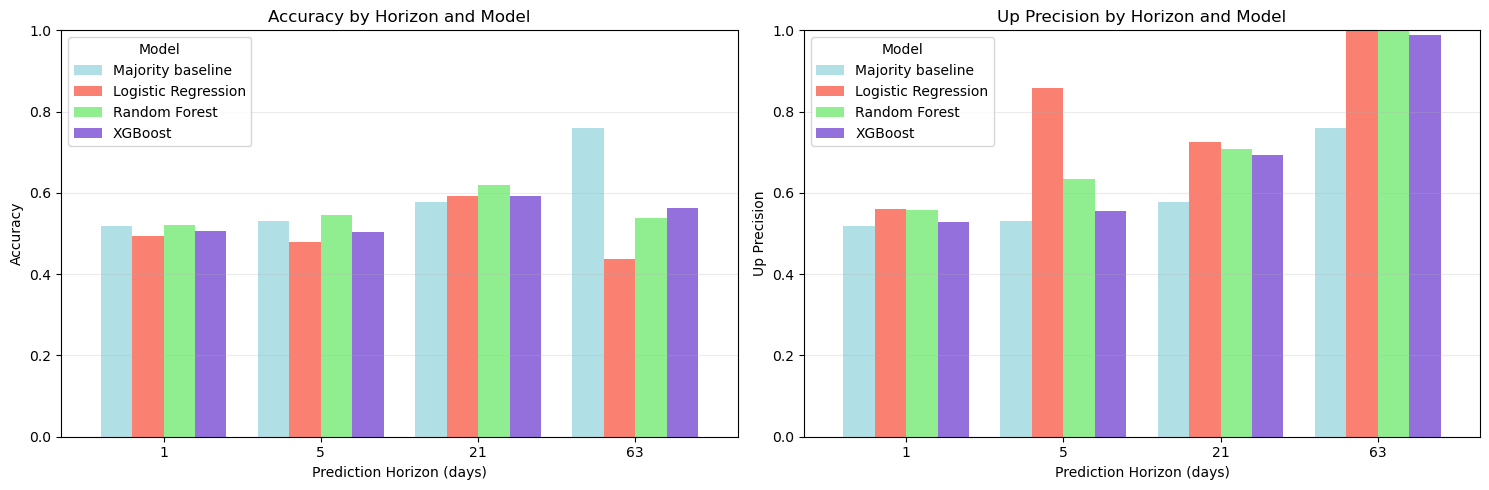

In [200]:
#Making accuracy + precision charts
model_order = ["Majority baseline", "Logistic Regression", "Random Forest", "XGBoost"]
model_colors = {"Majority baseline": "powderblue", 
                "Logistic Regression": "salmon", 
                "Random Forest": "lightgreen", 
                "XGBoost": "mediumpurple"}

#Make 1 chart for each metric
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
metrics_to_plot = [ ("Accuracy", "Accuracy"), ("Up precision", "Up Precision")]

for ax, (metric_col, metric_label) in zip(axes, metrics_to_plot):
    #One row per horizon, one column per model
    pivot = metrics_df.pivot( index="Horizon", columns="Model", values=metric_col)
    available_models = [ model for model in model_order if model in pivot.columns]
    pivot = pivot[available_models]

    #grouped bar chart
    pivot.plot(kind="bar", ax=ax, width=0.8, 
              color=[model_colors[model] for model in pivot.columns])

    ax.set_title(f"{metric_label} by Horizon and Model")
    ax.set_xlabel("Prediction Horizon (days)")
    ax.set_ylabel(metric_label)
    ax.set_ylim(0,1)
    ax.legend(title="Model")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()